# Stroke prediction: exploratory analysis and models

## Data

The data come from the [Stroke Prediction Dataset](https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset) on Kaggle (author: fedesoriano). Each row describes one patient; the target `stroke` indicates whether a stroke was recorded.

In [1]:
!pip install -q pandas numpy matplotlib seaborn scikit-learn imbalanced-learn wandb

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/healthcare-dataset-stroke-data.csv")

print("Dataset shape:", df.shape)
df.head()


Dataset shape: (5110, 12)


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   str    
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   str    
 6   work_type          5110 non-null   str    
 7   Residence_type     5110 non-null   str    
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   str    
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 634.7 KB


### Missing values detected

During the initial data check, a missing value (NaN) was detected in the `bmi` column. Given the clinical context, the absence of anthropometric data may not be coincidental — for example, in patients admitted in a critical condition, height and weight data may not have been recorded. This prompted a more thorough investigation into whether the nature of the missing values had any clinical significance.

In [4]:
df.isnull().sum()

id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

In [5]:
df['bmi_missing'] = df['bmi'].isnull()
df.groupby('bmi_missing')['stroke'].mean()

bmi_missing
False    0.042575
True     0.199005
Name: stroke, dtype: float64

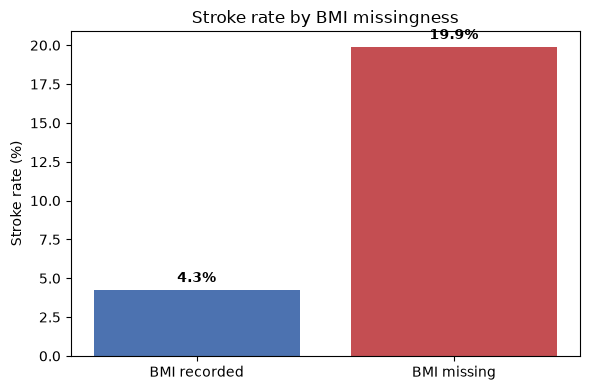

In [6]:
stroke_by_missing = df.groupby('bmi_missing')['stroke'].mean() * 100

plt.figure(figsize=(6, 4))
plt.bar(['BMI recorded', 'BMI missing'], stroke_by_missing, color=['#4C72B0', '#C44E52'])
plt.ylabel('Stroke rate (%)')
plt.title('Stroke rate by BMI missingness')

for i, value in enumerate(stroke_by_missing):
    plt.text(i, value + 0.5, f'{value:.1f}%', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

### Explanation

The incidence of strokes among patients with missing BMI values is 
almost five times higher (19.9 per cent) compared with patients for 
whom BMI values were recorded (4.3 per cent). Such a large gap is 
unlikely to arise purely by chance, reinforcing the interpretation 
that BMI missingness reflects a systematic, clinically meaningful 
pattern (MNAR — Missing Not At Random) rather than random noise, and 
is most likely associated with more severe or urgent clinical 
presentations in patients.

### Conclusion

Rows with missing BMI values will not be excluded, as this would lead 
to the disproportionate removal of stroke cases from an already 
imbalanced dataset. Instead, missing values will be imputed, and the 
`bmi_missing` indicator will be retained as a feature — the very fact 
that a BMI value is missing may have prognostic significance.

In [7]:
df['age_group'] = pd.cut(df['age'], bins=[0, 18, 40, 60, 80, 100],
                         labels=['0-18', '19-40', '41-60', '61-80', '81+'])

In [8]:
 df['age_group'].value_counts()

age_group
41-60    1562
19-40    1328
61-80    1188
0-18      916
81+       116
Name: count, dtype: int64

### Age distribution

The largest patient groups are middle-aged (41–60) and young adults 
(19–40), while the oldest group (81+) is the smallest — consistent 
with typical age distributions in medical datasets, where older 
patients are underrepresented.

In [9]:
df.groupby('age_group')['bmi'].median()

age_group
0-18     20.1
19-40    28.0
41-60    30.3
61-80    29.3
81+      27.5
Name: bmi, dtype: float64

In [10]:
df['bmi'] = df.groupby('age_group')['bmi'].transform(lambda x: x.fillna(x.median()))

In [11]:
df['bmi'].isnull().sum()

np.int64(0)

### Imputation method

Missing BMI values were imputed using the median BMI within each 
patient's age group, rather than a single overall median. BMI is known 
to vary systematically with age — a pattern also confirmed in this 
dataset, where the median BMI rises from 20.1 in the 0-18 age group to 
30.3 in the 41-60 group, before declining slightly in older age groups. 
Using a single dataset-wide median would have ignored this variation and 
introduced age-inappropriate values, particularly for younger and older 
patients at the extremes of the age distribution.

The `bmi_missing` indicator created earlier is preserved as a separate 
feature, so that the information lost through imputation — namely, the 
fact that a value was missing in the first place — remains available 
to the model.

In [12]:
df['stroke'].value_counts()

stroke
0    4861
1     249
Name: count, dtype: int64

In [13]:
df['stroke'].value_counts(normalize=True) * 100

stroke
0    95.127202
1     4.872798
Name: proportion, dtype: float64

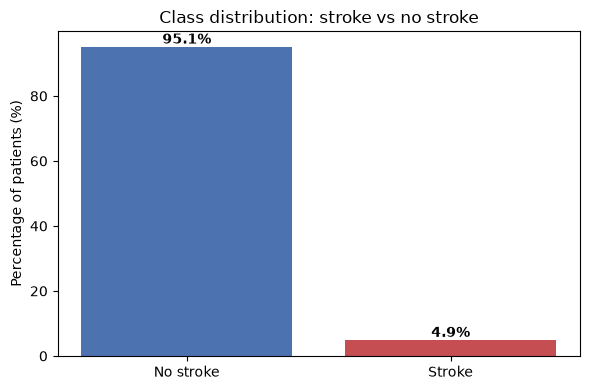

In [14]:
stroke_percent = df['stroke'].value_counts(normalize=True) * 100

plt.figure(figsize=(6, 4))
plt.bar(['No stroke', 'Stroke'], stroke_percent, color=['#4C72B0', '#C44E52'])
plt.ylabel('Percentage of patients (%)')
plt.title('Class distribution: stroke vs no stroke')

for i, value in enumerate(stroke_percent):
    plt.text(i, value + 1, f'{value:.1f}%', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

### Class imbalance

The target variable `stroke` is visualized as percentages rather than 
raw counts, since the imbalance itself — the relative proportion between 
classes — is the key issue, not the absolute number of cases.

Only 4.9% of patients in the dataset experienced a stroke, while the 
remaining 95.1% did not. This reflects the real-world rarity of stroke 
events in the general population, but it has important implications 
for modeling.

With such a strong imbalance, a model could achieve high accuracy simply 
by predicting "no stroke" for every patient — while completely failing 
to identify actual stroke cases, which are the ones that matter most 
clinically. For this reason, accuracy will not be used as the primary 
evaluation metric later in this project. Instead, precision, recall, 
F1-score, and ROC-AUC will be used, as they better reflect a model's 
ability to correctly identify the minority (stroke) class.

To address the imbalance directly, two approaches will be compared: 
class weighting, as a simpler and more interpretable method, and 
SMOTENC — a variant of SMOTE designed for datasets with a mix of 
continuous and categorical features (such as this one, following 
one-hot encoding), which avoids creating non-meaningful fractional 
values for binary columns. Both approaches will be evaluated using the 
metrics discussed above, and the more informative one will be carried 
forward for further modeling.

In [15]:
for col in ['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']:
    print(col, ':', df[col].unique())

gender : <ArrowStringArray>
['Male', 'Female', 'Other']
Length: 3, dtype: str
ever_married : <ArrowStringArray>
['Yes', 'No']
Length: 2, dtype: str
work_type : <ArrowStringArray>
['Private', 'Self-employed', 'Govt_job', 'children', 'Never_worked']
Length: 5, dtype: str
Residence_type : <ArrowStringArray>
['Urban', 'Rural']
Length: 2, dtype: str
smoking_status : <ArrowStringArray>
['formerly smoked', 'never smoked', 'smokes', 'Unknown']
Length: 4, dtype: str


In [16]:
df_encoded = pd.get_dummies(df, columns=['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status'], drop_first=True)

In [17]:
df_encoded.head()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke,bmi_missing,age_group,gender_Male,gender_Other,ever_married_Yes,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
0,9046,67.0,0,1,228.69,36.6,1,False,61-80,True,False,True,False,True,False,False,True,True,False,False
1,51676,61.0,0,0,202.21,29.3,1,True,61-80,False,False,True,False,False,True,False,False,False,True,False
2,31112,80.0,0,1,105.92,32.5,1,False,61-80,True,False,True,False,True,False,False,False,False,True,False
3,60182,49.0,0,0,171.23,34.4,1,False,41-60,False,False,True,False,True,False,False,True,False,False,True
4,1665,79.0,1,0,174.12,24.0,1,False,61-80,False,False,True,False,False,True,False,False,False,True,False


In [18]:
print('Columns before:', df.shape[1])
print('Columns after:', df_encoded.shape[1])

Columns before: 14
Columns after: 20


### Dropping `age_group`

The `age_group` column was created previously solely to enable 
age-adjusted BMI imputation and contains no information beyond that 
already reflected in the `age` column itself. Retaining it would 
therefore only introduce redundancy without adding predictive value, 
so it is removed.

In [19]:
df_encoded = df_encoded.drop(columns=['age_group'], errors='ignore')

In [20]:
'age_group' in df_encoded.columns

False

In [21]:
X = df_encoded.drop(columns=['stroke', 'id'])
y = df_encoded['stroke']

In [22]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

In [23]:
print('X_train:', X_train.shape)
print('X_test:', X_test.shape)
print('y_train:', y_train.shape)
print('y_test:', y_test.shape)

X_train: (4088, 17)
X_test: (1022, 17)
y_train: (4088,)
y_test: (1022,)


In [24]:
print('Train proportion:')
print(y_train.value_counts(normalize=True)*100)
print('Test proportion:')
print(y_test.value_counts(normalize=True)*100)

Train proportion:
stroke
0    95.132094
1     4.867906
Name: proportion, dtype: float64
Test proportion:
stroke
0    95.107632
1     4.892368
Name: proportion, dtype: float64


### Cross-validation

Given the small number of positive cases (only 249 stroke cases in the 
entire dataset), a single train/test split carries some risk of an 
unrepresentative or unstable evaluation — the exact composition of the 
test set could noticeably affect the reported metrics. To get a more 
reliable estimate of model performance, k-fold cross-validation will be 
used on the training set when evaluating and comparing models, rather 
than relying on a single train/test split alone. The held-out test set 
created above will still be reserved for a final, independent evaluation 
after model selection.

In [25]:
from sklearn.linear_model import LogisticRegression

model_lr = LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000)
model_lr.fit(X_train, y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default 

In [26]:
y_pred = model_lr.predict(X_test)

In [27]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.99      0.76      0.86       972
           1       0.14      0.80      0.25        50

    accuracy                           0.76      1022
   macro avg       0.57      0.78      0.55      1022
weighted avg       0.95      0.76      0.83      1022



In [28]:
from sklearn.metrics import recall_score

print('LR + class_weight, train recall:', recall_score(y_train, model_lr.predict(X_train)))
print('LR + class_weight, test recall:', recall_score(y_test, model_lr.predict(X_test)))

LR + class_weight, train recall: 0.8190954773869347
LR + class_weight, test recall: 0.8


### Logistic Regression results (class weighting)

With `class_weight='balanced'`, the model correctly identifies 80% of the 50 actual stroke cases in the test set (recall = 0.80 for the stroke class). This is the metric that matters most in this context: missing an actual stroke case has far greater clinical consequences than flagging a patient who turns out not to be at risk.

Recall on the training set (0.82) was close to recall on the test set (0.80), which does not indicate overfitting.

This recall comes at the cost of precision (0.14): only 14% of patients flagged as likely to have a stroke actually had one, meaning the model produces many false positives. In a screening context, this trade-off can be acceptable, because a screening tool is meant to narrow down who should receive closer clinical attention, not to provide a final diagnosis. How many false alarms are tolerable depends on the cost of follow-up examinations.

Overall accuracy (0.76) is reported for completeness but is not a reliable indicator of performance in this context, given the strong class imbalance discussed earlier.

In [29]:
categorical_features = [X_train.columns.get_loc(col) for col in X_train.columns if col not in ['age', 'avg_glucose_level', 'bmi']]

In [30]:
from imblearn.over_sampling import SMOTENC
smote_nc = SMOTENC(categorical_features=categorical_features, random_state=42)
X_train_smote, y_train_smote = smote_nc.fit_resample(X_train, y_train)

In [31]:
print('Continuous:', [col for col in X_train.columns if col not in X_train.columns[categorical_features]])

Continuous: ['age', 'avg_glucose_level', 'bmi']


In [32]:
print('Before SMOTENC:', X_train.shape)
print('After SMOTENC:', X_train_smote.shape)

Before SMOTENC: (4088, 17)
After SMOTENC: (7778, 17)


In [33]:
print(y_train_smote.value_counts(normalize=True) * 100)

stroke
0    50.0
1    50.0
Name: proportion, dtype: float64


In [34]:
model_lr_smote = LogisticRegression(random_state=42, max_iter=1000)
model_lr_smote.fit(X_train_smote, y_train_smote)

,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lb

In [35]:
y_pred_smote = model_lr_smote.predict(X_test)
print(classification_report(y_test, y_pred_smote))

              precision    recall  f1-score   support

           0       0.98      0.75      0.85       972
           1       0.13      0.74      0.22        50

    accuracy                           0.75      1022
   macro avg       0.56      0.74      0.54      1022
weighted avg       0.94      0.75      0.82      1022



In [36]:
print('LR + SMOTENC, train recall:', recall_score(y_train, model_lr_smote.predict(X_train)))
print('LR + SMOTENC, test recall:', recall_score(y_test, model_lr_smote.predict(X_test)))

LR + SMOTENC, train recall: 0.7286432160804021
LR + SMOTENC, test recall: 0.74


### Comparing class weighting and `SMOTENC`

Having already seen strong results from class weighting, `SMOTENC` was tested as an alternative to check whether it could offer any further improvement. It did not improve recall in this experiment: class weighting achieved a recall of 0.80 for the stroke class, compared with 0.74 for `SMOTENC`, with comparable precision (0.14 vs. 0.13). The difference corresponds to about three stroke cases out of the 50 in the test set.

Neither variant showed signs of overfitting: recall on the training set (0.82 for `class_weight='balanced'`, 0.73 for `SMOTENC`) was close to recall on the test set (0.80 and 0.74). For `SMOTENC`, training recall was computed on the original training set rather than the resampled one.

One possible explanation for the weaker `SMOTENC` result is the composition of this dataset: 14 of the 17 features are binary after one-hot encoding, so synthetic examples can differ from real patients only in the three continuous features (`age`, `avg_glucose_level`, `bmi`), which may add little useful diversity. Additionally, `class_weight='balanced'` acts directly on the loss function during training, which may be particularly effective for linear models such as Logistic Regression. Neither explanation was tested directly.

In [37]:
from sklearn.ensemble import RandomForestClassifier

model_rf = RandomForestClassifier(class_weight='balanced', random_state=42)
model_rf.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.

In [38]:
y_pred_rf = model_rf.predict(X_test)
print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       0.96      0.98      0.97       972
           1       0.28      0.14      0.19        50

    accuracy                           0.94      1022
   macro avg       0.62      0.56      0.58      1022
weighted avg       0.92      0.94      0.93      1022



In [39]:
from sklearn.metrics import recall_score

y_train_pred = model_rf.predict(X_train)
y_test_pred = model_rf.predict(X_test)

print('RF 100 trees, train recall:', recall_score(y_train, y_train_pred))
print('RF 100 trees, test recall:', recall_score(y_test, y_test_pred))

RF 100 trees, train recall: 1.0
RF 100 trees, test recall: 0.14


In [40]:
model_rf_smote = RandomForestClassifier(random_state=42)
model_rf_smote.fit(X_train_smote, y_train_smote)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [41]:
y_pred_rf_smote = model_rf_smote.predict(X_test)
print(classification_report(y_test, y_pred_rf_smote))

              precision    recall  f1-score   support

           0       0.96      0.95      0.95       972
           1       0.14      0.16      0.15        50

    accuracy                           0.91      1022
   macro avg       0.55      0.55      0.55      1022
weighted avg       0.92      0.91      0.91      1022



In [42]:
print('RF + SMOTENC, train recall:', recall_score(y_train, model_rf_smote.predict(X_train)))
print('RF + SMOTENC, test recall:', recall_score(y_test, model_rf_smote.predict(X_test)))

RF + SMOTENC, train recall: 1.0
RF + SMOTENC, test recall: 0.16


In [43]:
model_rf_v2 = RandomForestClassifier(class_weight='balanced_subsample', random_state=42)
model_rf_v2.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced_subsample'
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionch

In [44]:
y_pred_rf_v2 = model_rf_v2.predict(X_test)
print(classification_report(y_test, y_pred_rf_v2, zero_division=0))

              precision    recall  f1-score   support

           0       0.95      1.00      0.97       972
           1       0.00      0.00      0.00        50

    accuracy                           0.95      1022
   macro avg       0.48      0.50      0.49      1022
weighted avg       0.90      0.95      0.93      1022



In [45]:
print('RF + balanced_subsample, train recall:', recall_score(y_train, model_rf_v2.predict(X_train)))
print('RF + balanced_subsample, test recall:', recall_score(y_test, model_rf_v2.predict(X_test)))

RF + balanced_subsample, train recall: 1.0
RF + balanced_subsample, test recall: 0.0


In [46]:
model_rf_v3 = RandomForestClassifier(class_weight='balanced', n_estimators=300, random_state=42)
model_rf_v3.fit(X_train, y_train)

y_pred_rf_v3 = model_rf_v3.predict(X_test)
print(classification_report(y_test, y_pred_rf_v3))

              precision    recall  f1-score   support

           0       0.96      0.98      0.97       972
           1       0.24      0.12      0.16        50

    accuracy                           0.94      1022
   macro avg       0.60      0.55      0.56      1022
weighted avg       0.92      0.94      0.93      1022



In [47]:
y_train_pred = model_rf_v3.predict(X_train)
y_test_pred = model_rf_v3.predict(X_test)

print('RF 300 trees, train recall:', recall_score(y_train, y_train_pred))
print('RF 300 trees, test recall:', recall_score(y_test, y_test_pred))

RF 300 trees, train recall: 1.0
RF 300 trees, test recall: 0.12


### Random Forest — comparing imbalance-handling strategies

Several approaches to handling class imbalance were tested with Random Forest, and none matched the recall achieved by Logistic Regression:

* `class_weight='balanced'`: recall 0.14
* `SMOTENC`-resampled training data: recall 0.16
* `class_weight='balanced_subsample'`: recall 0.00 (the model failed to predict the stroke class at all on the test set)
* `class_weight='balanced'` with 300 trees (up from the default 100): recall 0.12

For all four variants, recall on the training set was compared with recall on the test set (see the overfitting checks in the cells above). Every variant reached a training recall of 1.0, against test recall between 0.00 and 0.16, which points to overfitting. For the `SMOTENC` variant, training recall was computed on the original training set rather than the resampled one.

One possible explanation for the weaker generalization is that the relationship between the features and stroke risk is largely linear, which favors Logistic Regression, while Random Forest fits nonlinear patterns that may be noise given the small number of positive cases (249 in the full dataset). This explanation was not tested directly.

Random Forest will not be used as the final model for this project.

In [48]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [49]:
print('Mean before scaling:', X_train['age'].mean())
print('Mean after scaling:', X_train_scaled[:,X_train.columns.get_loc('age')].mean())

Mean before scaling: 43.35328767123288
Mean after scaling: -1.5643064143446432e-17


In [50]:
from sklearn.svm import SVC

model_svm = SVC(class_weight='balanced', random_state=42)
model_svm.fit(X_train_scaled, y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",'balanced'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forprobability estimates. Ignored when `probability` is False.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200


In [51]:
y_pred_svm = model_svm.predict(X_test_scaled)
print(classification_report(y_test, y_pred_svm))

              precision    recall  f1-score   support

           0       0.98      0.79      0.87       972
           1       0.15      0.72      0.25        50

    accuracy                           0.78      1022
   macro avg       0.57      0.75      0.56      1022
weighted avg       0.94      0.78      0.84      1022



In [52]:
print('SVC rbf, train recall:', recall_score(y_train, model_svm.predict(X_train_scaled)))
print('SVC rbf, test recall:', recall_score(y_test, model_svm.predict(X_test_scaled)))

SVC rbf, train recall: 0.9396984924623115
SVC rbf, test recall: 0.72


In [53]:
model_svm_linear = SVC(kernel='linear', class_weight='balanced', random_state=42)
model_svm_linear.fit(X_train_scaled, y_train)

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",'balanced'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forprobability estimates. Ignored when `probability` is False.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200


In [54]:
y_pred_svm_linear = model_svm_linear.predict(X_test_scaled)
print(classification_report(y_test, y_pred_svm_linear))

              precision    recall  f1-score   support

           0       0.99      0.75      0.85       972
           1       0.14      0.78      0.24        50

    accuracy                           0.75      1022
   macro avg       0.56      0.77      0.55      1022
weighted avg       0.94      0.75      0.82      1022



In [55]:
print('SVC linear, train recall:', recall_score(y_train, model_svm_linear.predict(X_train_scaled)))
print('SVC linear, test recall:', recall_score(y_test, model_svm_linear.predict(X_test_scaled)))

SVC linear, train recall: 0.8291457286432161
SVC linear, test recall: 0.78


### SVC results

After several attempts to improve Random Forest's performance did not approach the recall of Logistic Regression, SVC (the classification variant of SVM) was introduced as a third algorithm. With the default RBF kernel, which allows a nonlinear decision boundary, SVC reached a recall of 0.72, a marked improvement over every Random Forest variant (best recall: 0.16). Recall on the training set (0.94) was much higher than on the test set (0.72), which points to overfitting. `C` and `gamma` were left at their defaults and not tuned, so this does not show that a tuned RBF model would behave the same way.

This result suggested a hypothesis: the relationship between the features and stroke risk might be largely linear, which would also explain Random Forest's weaker performance. To probe this, a second SVC model was fit with `kernel='linear'`, restricting the decision boundary to a linear one. It reached a recall of 0.78, comparable to Logistic Regression's 0.80. Training recall (0.83) was close to test recall (0.78), which does not indicate substantial overfitting.

This result is consistent with the hypothesis, but does not prove it. The difference between 0.72 and 0.78 corresponds to about three stroke cases in the test set (50 cases in total), and the RBF kernel was not tuned.

In [56]:
import pandas as pd

results_df = pd.DataFrame({
    'model': ['LR + class_weight', 'LR + SMOTENC', 'RF + class_weight', 'RF + SMOTENC', 'RF + balanced_subsample', 'RF + 300 trees', 'SVC rbf', 'SVC linear'],
    'precision': [0.14, 0.13, 0.28, 0.14, 0.00, 0.24, 0.15, 0.14],
    'recall': [0.80, 0.74, 0.14, 0.16, 0.00, 0.12, 0.72, 0.78],
    'f1': [0.25, 0.22, 0.19, 0.15, 0.00, 0.16, 0.24, 0.24]
})
results_df    

,model,precision,recall,f1
0,LR + class_weight,0.14,0.80,0.25
1,LR + SMOTENC,0.13,0.74,0.22
2,RF + class_weight,0.28,0.14,0.19
3,RF + SMOTENC,0.14,0.16,0.15
4,RF + balanced_subsample,0.00,0.00,0.00
5,RF + 300 trees,0.24,0.12,0.16
6,SVC rbf,0.15,0.72,0.24
7,SVC linear,0.14,0.78,0.24


In [57]:
results_df.sort_values('recall', ascending=False)

,model,precision,recall,f1
0,LR + class_weight,0.14,0.80,0.25
7,SVC linear,0.14,0.78,0.24
1,LR + SMOTENC,0.13,0.74,0.22
6,SVC rbf,0.15,0.72,0.24
3,RF + SMOTENC,0.14,0.16,0.15
2,RF + class_weight,0.28,0.14,0.19
5,RF + 300 trees,0.24,0.12,0.16
4,RF + balanced_subsample,0.00,0.00,0.00


In [58]:
best_model = results_df.loc[results_df['recall'].idxmax()]
print(best_model)

model        LR + class_weight
precision                 0.14
recall                     0.8
f1                        0.25
Name: 0, dtype: object


In [98]:
import wandb

LOG_TO_WANDB = False

if LOG_TO_WANDB:
    wandb.login()

In [60]:
if LOG_TO_WANDB:
    for index, row in results_df.iterrows():
        run = wandb.init(project='stroke-prediction', name=row['model'], reinit=True)
        wandb.log({
            'precision': row['precision'],
            'recall': row['recall'],
            'f1': row['f1']
        })
        run.finish()

In [61]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [62]:
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

In [63]:
lr_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('lr', LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000))
])

lr_cv_scores = cross_val_score(lr_pipeline, X_train, y_train, cv=cv, scoring='recall')

print('LR (scaled in each fold), recall per fold:', lr_cv_scores)
print(f'Mean: {lr_cv_scores.mean():.3f} ± {lr_cv_scores.std():.3f}')

LR (scaled in each fold), recall per fold: [0.8        0.85       0.75       0.82051282 0.75      ]
Mean: 0.794 ± 0.039


In [64]:
from imblearn.pipeline import Pipeline as ImbPipeline 

In [65]:
pipeline_rf = ImbPipeline([
    ('smotenc', SMOTENC(categorical_features=categorical_features, random_state=42)),
    ('model', RandomForestClassifier(random_state=42))
])

scores_rf = cross_val_score(pipeline_rf, X_train, y_train, cv=cv, scoring='recall')

In [66]:
print('RF recall per fold:', scores_rf)
print('RF mean recall:', scores_rf.mean())
print('RF std recall:', scores_rf.std())

RF recall per fold: [0.15       0.25       0.2        0.28205128 0.175     ]
RF mean recall: 0.2114102564102564
RF std recall: 0.04838686418754588


In [67]:
svc_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svc', SVC(kernel='linear', class_weight='balanced', random_state=42))
])

svc_cv_scores = cross_val_score(svc_pipeline, X_train, y_train, cv=cv, scoring='recall')

print('SVC linear (scaled in each fold), recall per fold:', svc_cv_scores)
print(f'Mean: {svc_cv_scores.mean():.3f} ± {svc_cv_scores.std():.3f}')

SVC linear (scaled in each fold), recall per fold: [0.8        0.85       0.775      0.84615385 0.8       ]
Mean: 0.814 ± 0.029


In [68]:
cv_results_df = pd.DataFrame({
    'model': ['Logistic Regression', 'Random Forest', 'SVC linear'],
    'mean_recall': [lr_cv_scores.mean(), scores_rf.mean(), svc_cv_scores.mean()],
    'std_recall': [lr_cv_scores.std(), scores_rf.std(), svc_cv_scores.std()]
})
cv_results_df

,model,mean_recall,std_recall
0,Logistic Regression,0.794103,0.039362
1,Random Forest,0.211410,0.048387
2,SVC linear,0.814231,0.029129


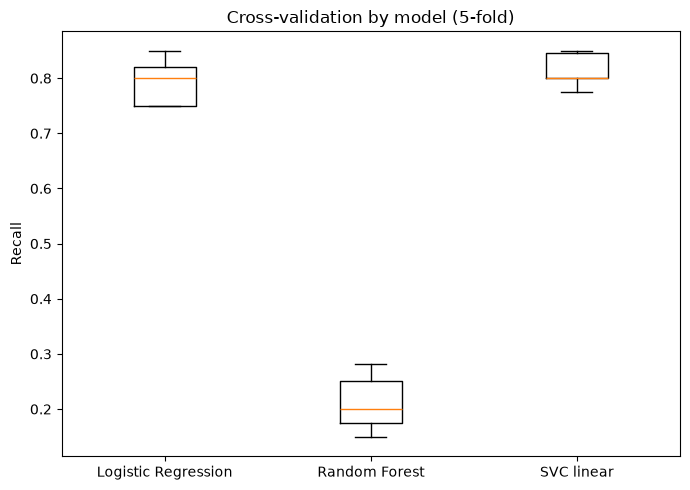

In [69]:
plt.figure(figsize=(7, 5))
plt.boxplot([lr_cv_scores, scores_rf, svc_cv_scores], tick_labels=['Logistic Regression', 'Random Forest', 'SVC linear'])
plt.ylabel('Recall')
plt.title('Cross-validation by model (5-fold)')
plt.tight_layout()
plt.show()

In [70]:
cv_results = {
    'Logistic Regression (CV)': lr_cv_scores,
    'Random Forest (CV)': scores_rf,
    'SVC linear (CV)': svc_cv_scores
}

if LOG_TO_WANDB:
    for model_name, scores in cv_results.items():
        run = wandb.init(project='stroke-prediction', name=model_name, reinit=True)
        wandb.log({
            'mean_recall': scores.mean(),
            'std_recall': scores.std(),
            'min_recall': scores.min(),
            'max_recall': scores.max()
        })
        run.finish()

### Cross-validation results

On a single train/test split, Logistic Regression (recall 0.80) was marginally ahead of SVC with a linear kernel (recall 0.78), and both far outperformed every Random Forest variant. Because the two leading models were so close, 5-fold stratified cross-validation was applied to the best-performing configuration of each of the three algorithms. For Logistic Regression and SVC, scaling was done inside each fold with a `Pipeline`, so that no information from the validation fold leaked into the scaler.

SVC reached a mean recall of 0.814 (± 0.029), compared with 0.794 (± 0.039) for Logistic Regression and 0.211 (± 0.048) for Random Forest. Here, ± is the standard deviation of recall across the five folds. SVC scored equal to or higher than Logistic Regression in all five folds, but the mean difference of 0.02 corresponds to roughly one stroke case per fold and is smaller than the fold-to-fold variation. The two linear models are therefore treated as comparable on recall. Scaling did not change the Logistic Regression result.

Random Forest remained far below both linear models and also showed the highest variability across folds. The box plot below shows the five fold scores per model; with only five points per box, it indicates spread only roughly.

## Feature importance

This section examines which features drive the predictions of Logistic Regression. The model was refit on the full training set inside a `Pipeline` with `StandardScaler`, because the cross-validation pipeline is trained fold by fold and is not fitted on the whole training set. Standardization puts all features on a common scale, so coefficients can be compared across features. The test set was not used for the coefficients. The model uses `class_weight='balanced'`, so the order and signs of the coefficients are informative, while their magnitudes should be read as approximate.

In [71]:
# Refit on the full training set; the CV pipeline was not fitted on it
lr_pipeline.fit(X_train, y_train)

coef_df = pd.DataFrame({
    'feature': X_train.columns,
    'coefficient': lr_pipeline.named_steps['lr'].coef_[0]
})
coef_df['abs_coefficient'] = coef_df['coefficient'].abs()
coef_df = coef_df.sort_values('abs_coefficient', ascending=False)
coef_df.round(3)

,feature,coefficient,abs_coefficient
0,age,1.843,1.843
12,work_type_children,0.392,0.392
5,bmi_missing,0.333,0.333
1,hypertension,0.199,0.199
16,smoking_status_smokes,0.196,0.196
3,avg_glucose_level,0.177,0.177
9,work_type_Never_worked,-0.154,0.154
14,smoking_status_formerly smoked,0.110,0.110
11,work_type_Self-employed,-0.107,0.107
4,bmi,0.094,0.094


### Coefficients sorted by absolute value

`age` has by far the largest coefficient (1.84). The next features are `work_type_children` (0.39), `bmi_missing` (0.33), `hypertension` (0.20), `smoking_status_smokes` (0.20) and `avg_glucose_level` (0.18), all with positive signs. Two of these, `work_type_children` and `bmi_missing`, reflect data artifacts rather than clinical risk factors and are discussed below.

In [72]:
import numpy as np

scale = pd.Series(lr_pipeline.named_steps['scaler'].scale_, index=X_train.columns)

coef_df['odds_ratio_per_SD'] = np.exp(coef_df['coefficient'])
coef_df['odds_ratio_per_unit'] = np.exp(coef_df['coefficient'] / coef_df['feature'].map(scale))
coef_df

,feature,coefficient,abs_coefficient,odds_ratio_per_SD,odds_ratio_per_unit
0,age,1.843317,1.843317,6.317458,1.085005
12,work_type_children,0.392112,0.392112,1.480103,3.144324
5,bmi_missing,0.333269,0.333269,1.395523,5.308754
1,hypertension,0.199091,0.199091,1.220293,1.958836
16,smoking_status_smokes,0.195511,0.195511,1.215933,1.721017
3,avg_glucose_level,0.177075,0.177075,1.193720,1.003921
9,work_type_Never_worked,-0.153745,0.153745,0.857491,0.065173
14,smoking_status_formerly smoked,0.109526,0.109526,1.115749,1.334388
11,work_type_Self-employed,-0.107334,0.107334,0.898226,0.747909
4,bmi,0.094483,0.094483,1.099090,1.012215


### Full coefficient table

The table lists the coefficients of all 17 features from Logistic Regression refit on the full training set (`StandardScaler` inside a `Pipeline`), sorted by absolute value. `odds_ratio_per_SD` is the exponentiated coefficient, i.e. the change in odds per one standard deviation of the feature. `odds_ratio_per_unit` converts this to the natural unit of the feature (`coefficient / scale`, exponentiated): one year of `age`, one mg/dL of `avg_glucose_level`, or the presence of a binary feature.

Per-unit values for very rare binary features are unreliable. For `gender_Other` (1 row) and `work_type_Never_worked` (13 rows), the standard deviation is close to zero, so the conversion produces extreme values (0.02 and 0.07) that carry no information. These two features were therefore excluded from the chart and from the summary table below. `bmi_missing` and `work_type_children` reflect data artifacts rather than clinical risk factors (see the section on artifacts).

In [73]:
ages = X_train.loc[X_train['work_type_children'] == 1, 'age']

pd.DataFrame({
    'patients': [len(ages)],
    'min': [ages.min()],
    'mean': [ages.mean()],
    'median': [ages.median()],
    'max': [ages.max()]
}).style.hide(axis='index').format({
    'patients': '{:d}', 'min': '{:.2f}', 'mean': '{:.1f}', 'median': '{:.0f}', 'max': '{:.0f}'
})

patients,min,mean,median,max
554,0.08,6.8,6,16


### Age of patients in `work_type_children`

All 554 training patients with `work_type_children` are aged 16 years or younger (range 0.08 to 16, mean 6.8, median 6). The column therefore largely coincides with very young age.

In [74]:
X_train[['gender_Other', 'work_type_Never_worked', 'work_type_children']].sum().rename('training rows').to_frame()

,training rows
gender_Other,1
work_type_Never_worked,13
work_type_children,554


### Rare categories

`gender_Other` has 1 training row and `work_type_Never_worked` has 13, so their coefficients cannot be interpreted: a model fitted on a single row learns nothing general, and for 13 rows the estimate is dominated by chance. `work_type_children` (554 rows) is not rare.

In [75]:
X_train[['age', 'hypertension', 'heart_disease']].corr().round(2)

,age,hypertension,heart_disease
age,1.00,0.27,0.27
hypertension,0.27,1.00,0.09
heart_disease,0.27,0.09,1.00


### Correlations between `age`, `hypertension` and `heart_disease`

`age` correlates moderately with both `hypertension` and `heart_disease` (0.27 in each case), while the correlation between `hypertension` and `heart_disease` is weak (0.09). Part of the effect of the two conditions may therefore be shared with `age` in the model.

In [76]:
X_train.groupby('heart_disease')['age'].mean().round(1).rename('mean age').to_frame()

,mean age
heart_disease,
0,41.9
1,68.6


### Mean age by `heart_disease`

Patients with `heart_disease` are considerably older than those without it (mean age 68.6 vs. 41.9 years).

In [77]:
X_no_age = X_train.drop(columns=['age'])

lr_no_age = Pipeline([
    ('scaler', StandardScaler()),
    ('lr', LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000))
])
lr_no_age.fit(X_no_age, y_train)

no_age_df = pd.DataFrame({
    'feature': X_no_age.columns,
    'coefficient': lr_no_age.named_steps['lr'].coef_[0]
})
no_age_df[no_age_df['feature'].isin(['heart_disease', 'hypertension', 'avg_glucose_level'])]

,feature,coefficient
0,hypertension,0.332656
1,heart_disease,0.246597
2,avg_glucose_level,0.281773


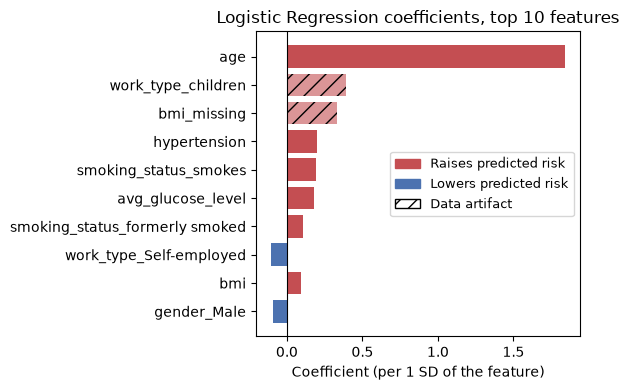

In [78]:
from matplotlib.patches import Patch

exclude = ['gender_Other', 'work_type_Never_worked']
artifacts = ['bmi_missing', 'work_type_children']

plot_df = coef_df[~coef_df['feature'].isin(exclude)].head(10).sort_values('abs_coefficient')
colors = ['#C44E52' if c > 0 else '#4C72B0' for c in plot_df['coefficient']]

plt.figure(figsize=(6, 4))
bars = plt.barh(plot_df['feature'], plot_df['coefficient'], color=colors)

for bar, feature in zip(bars, plot_df['feature']):
    if feature in artifacts:
        bar.set_hatch('//')
        bar.set_alpha(0.6)

plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('Coefficient (per 1 SD of the feature)')
plt.title('Logistic Regression coefficients, top 10 features')
plt.legend(handles=[
    Patch(color='#C44E52', label='Raises predicted risk'),
    Patch(color='#4C72B0', label='Lowers predicted risk'),
    Patch(facecolor='white', edgecolor='black', hatch='//', label='Data artifact')
], loc='center right', fontsize=9)
plt.tight_layout()
plt.show()

### Logistic Regression coefficients

Coefficients were taken from Logistic Regression with `class_weight='balanced'`, refit on the full training set inside a `Pipeline` with `StandardScaler`. Because all features share a common scale, coefficients are comparable across features; each one is the change in log-odds per one standard deviation of the feature. The test set was not used.

`age` has by far the largest coefficient (1.84, against 0.39 for the next feature). Red bars raise the predicted risk, blue bars lower it. Hatched bars mark features that reflect data artifacts rather than clinical risk factors (see below). `gender_Other` (1 row) and `work_type_Never_worked` (13 rows) were omitted because they are too rare to interpret. Because the model was trained with `class_weight='balanced'`, the order and signs of the coefficients are informative, while their magnitudes should be read as approximate.

In [79]:
coef = coef_df.set_index('feature')['coefficient']

or_table = pd.DataFrame({
    'feature': ['age (per year)', 'age (per 10 years)', 'avg_glucose_level (per 10 mg/dL)',
                'hypertension (yes vs. no)', 'heart_disease (yes vs. no)',
                'smoking_status_smokes (vs. Unknown)',
                'smoking_status_formerly smoked (vs. Unknown)'],
    'odds_ratio': [
        np.exp(coef['age'] / scale['age']),
        np.exp(10 * coef['age'] / scale['age']),
        np.exp(10 * coef['avg_glucose_level'] / scale['avg_glucose_level']),
        np.exp(coef['hypertension'] / scale['hypertension']),
        np.exp(coef['heart_disease'] / scale['heart_disease']),
        np.exp(coef['smoking_status_smokes'] / scale['smoking_status_smokes']),
        np.exp(coef['smoking_status_formerly smoked'] / scale['smoking_status_formerly smoked'])
    ]
})
or_table.style.hide(axis='index').format({'odds_ratio': '{:.2f}'})

feature,odds_ratio
age (per year),1.09
age (per 10 years),2.26
avg_glucose_level (per 10 mg/dL),1.04
hypertension (yes vs. no),1.96
heart_disease (yes vs. no),1.28
smoking_status_smokes (vs. Unknown),1.72
smoking_status_formerly smoked (vs. Unknown),1.33


### Odds ratios in interpretable units

Coefficients were converted to odds ratios per natural unit of each feature (`coefficient / scale`, exponentiated): per year or per 10 years for `age`, per 10 mg/dL for `avg_glucose_level`, and for the presence of the condition for binary features. `bmi` contributes little (odds ratio 1.06 per 5 units).

The reference category for smoking status is `Unknown` (missing status). It comprises 1,247 training patients with a mean age of 30.8 years, so the values for `smoking_status_smokes` and `smoking_status_formerly smoked` are not comparisons with non-smokers, and they may partly reflect differences in age composition. This was not tested directly. For the same reason, `smoking_status_never smoked` (coefficient 0.03) differs little from the reference.

These values are approximate: they come from a model trained with `class_weight='balanced'`, without confidence intervals, on a single train/test split. The order and direction of the effects are informative; the magnitudes should not be read as exact risk estimates.

In [80]:
# Check only: refit without work_type_children; not a candidate model
X_no_children = X_train.drop(columns=['work_type_children'])

lr_no_children = Pipeline([
    ('scaler', StandardScaler()),
    ('lr', LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000))
])
lr_no_children.fit(X_no_children, y_train)

no_children_df = pd.DataFrame({
    'feature': X_no_children.columns,
    'coefficient': lr_no_children.named_steps['lr'].coef_[0]
})
no_children_df[no_children_df['feature'].isin(['age', 'hypertension', 'heart_disease'])]

,feature,coefficient
0,age,1.776045
1,hypertension,0.199464
2,heart_disease,0.058647


### Features reflecting data artifacts

Two of the largest coefficients do not describe clinical risk factors.

- `bmi_missing`: this feature reflects a pattern in missing data rather than a risk factor. In the training data, stroke was more frequent among patients with a missing `bmi` (19.9% vs. 4.3%).
- `work_type_children`: all 554 training patients in this category are 16 years old or younger (mean age 6.8), so the feature largely coincides with very young age. Its positive coefficient is clinically implausible as a causal effect. Refitting the model without this column changed the coefficient for `age` only slightly (from 1.84 to 1.78), so the reason for the positive coefficient was not identified. The model without this column was used only for this check.

In [81]:
svc_pipeline.fit(X_train, y_train)

svc_coef = pd.Series(svc_pipeline.named_steps['svc'].coef_[0], index=X_train.columns)

compare_df = pd.DataFrame({
    'LR': coef,
    'SVC linear': svc_coef
})
compare_df['LR rank'] = compare_df['LR'].abs().rank(ascending=False).astype(int)
compare_df['SVC rank'] = compare_df['SVC linear'].abs().rank(ascending=False).astype(int)
compare_df['same sign'] = (compare_df['LR'] * compare_df['SVC linear']) > 0
compare_df.sort_values('LR rank').round(3)

,LR,SVC linear,LR rank,SVC rank,same sign
age,1.843,1.472,1,1,True
work_type_children,0.392,0.656,2,2,True
bmi_missing,0.333,0.182,3,3,True
hypertension,0.199,0.121,4,6,True
smoking_status_smokes,0.196,0.170,5,4,True
avg_glucose_level,0.177,0.146,6,5,True
work_type_Never_worked,-0.154,-0.000,7,16,True
smoking_status_formerly smoked,0.110,0.052,8,9,True
work_type_Self-employed,-0.107,-0.012,9,14,True
bmi,0.094,0.030,10,13,True


### Comparison with SVC (linear kernel)

Coefficients of SVC with a linear kernel, refit on the full training set inside a `Pipeline` with `StandardScaler`, were compared with those of Logistic Regression by rank and sign. Magnitudes are not directly comparable, since the two models use different scales. The top three features by absolute coefficient are identical (`age`, `work_type_children`, `bmi_missing`), and signs agree for 15 of 17 features. The two exceptions (`gender_Other` and `smoking_status_never smoked`) have coefficients close to zero, so the sign differences carry no information. Both models rank `heart_disease` low. The interpretation therefore does not depend on the choice between the two models. Both are linear and see the same data, so agreement does not show that the effects are real. `C` was left at its default for both models.

In [82]:
from sklearn.metrics import precision_score

thr = np.percentile(X_train.loc[y_train == 1, 'age'], 20)
pred_age = (X_test['age'] >= thr).astype(int)

print(f'Age threshold: {thr:.0f} years')
print(f'recall: {recall_score(y_test, pred_age):.2f}')
print(f'precision: {precision_score(y_test, pred_age):.2f}')

Age threshold: 57 years
recall: 0.84
precision: 0.13


### Baseline: age threshold

As a reference, a rule that flags every patient aged 57 or older was evaluated on the test set. The threshold is the 20th percentile of age among stroke cases in the training set, so the test set was not used to choose it. The rule reached recall 0.84 and precision 0.13, comparable to Logistic Regression (0.80 and 0.14). This suggests that most of the predictive signal in these models comes from `age`. The differences correspond to one or two stroke cases out of 50, and the threshold follows a single arbitrary rule, so this is a rough reference rather than a full comparison.

In [83]:
from sklearn.metrics import roc_auc_score

auc_lr = roc_auc_score(y_test, lr_pipeline.predict_proba(X_test)[:, 1])
auc_svc = roc_auc_score(y_test, svc_pipeline.decision_function(X_test))
auc_age = roc_auc_score(y_test, X_test['age'])

print(f'LR AUC: {auc_lr:.3f}')
print(f'SVC linear AUC: {auc_svc:.3f}')
print(f'Age only AUC: {auc_age:.3f}')

LR AUC: 0.843
SVC linear AUC: 0.845
Age only AUC: 0.834


In [84]:
from sklearn.compose import ColumnTransformer

cv_auc_lr = cross_val_score(lr_pipeline, X_train, y_train, cv=cv, scoring='roc_auc')
cv_auc_svc = cross_val_score(svc_pipeline, X_train, y_train, cv=cv, scoring='roc_auc')

# Reference model that uses age only
cv_auc_age = cross_val_score(
    Pipeline([('select', ColumnTransformer([('age', 'passthrough', ['age'])])),
              ('lr', LogisticRegression(max_iter=1000))]),
    X_train, y_train, cv=cv, scoring='roc_auc')

for name, s in [('LR', cv_auc_lr), ('SVC linear', cv_auc_svc), ('Age only', cv_auc_age)]:
    print(f'{name}: {s.mean():.3f} ± {s.std():.3f}')

LR: 0.853 ± 0.009
SVC linear: 0.851 ± 0.012
Age only: 0.834 ± 0.016


### ROC-AUC

ROC-AUC measures how well a score ranks patients, regardless of any threshold: 0.5 corresponds to random ranking and 1.0 to perfect ranking. Three scores were compared: the predicted probability of Logistic Regression, the decision function of SVC with a linear kernel (SVC has no probabilities by default), and `age` alone.

On the test set, ROC-AUC was 0.843 for Logistic Regression, 0.845 for SVC and 0.834 for `age` alone. In 5-fold cross-validation on the training set, the mean was 0.853 (± 0.009) for Logistic Regression, 0.851 (± 0.012) for SVC and 0.834 (± 0.016) for a Logistic Regression model using `age` alone. Here, ± is the standard deviation across the five folds.

The two linear models are indistinguishable by this metric. Both rank patients about 0.02 better than `age` alone in cross-validation and about 0.01 better on the test set, which contains only 50 stroke cases. Most of the predictive signal therefore comes from `age`. Whether the remaining features add anything is examined in the bootstrap check below. The cross-validation folds are not independent, so no significance test was applied to those results.

In [85]:
rng = np.random.default_rng(42)

y_arr = y_test.to_numpy()
score_lr = lr_pipeline.predict_proba(X_test)[:, 1]
score_age = X_test['age'].to_numpy()

diffs = []
for _ in range(2000):
    idx = rng.integers(0, len(y_arr), len(y_arr))
    if y_arr[idx].sum() == 0:
        continue
    diffs.append(roc_auc_score(y_arr[idx], score_lr[idx]) - roc_auc_score(y_arr[idx], score_age[idx]))

low, high = np.percentile(diffs, [2.5, 97.5])
print(f'AUC difference (LR minus age): mean {np.mean(diffs):.3f}, 95% interval [{low:.3f}, {high:.3f}]')

AUC difference (LR minus age): mean 0.009, 95% interval [-0.010, 0.028]


### Bootstrap check of the AUC difference

To check whether the test-set difference between Logistic Regression and `age` alone could be due to chance, test patients were resampled with replacement 2,000 times, and the AUC difference was recomputed on each resample for both scores. The mean difference was 0.009, with a 95% interval of [-0.010, 0.028], which includes zero. On this test set, the added value of the full model over `age` alone is therefore not demonstrated. The bootstrap reflects only sampling variation in the 50 test stroke cases and not variation in the trained model.

In [86]:
age_bins = pd.cut(X_train['age'], bins=[0, 18, 40, 60, 80, 100])
print(y_train.groupby(age_bins, observed=True).agg(['sum', 'count', 'mean']).round(3))

           sum  count   mean
age                         
(0, 18]      1    725  0.001
(18, 40]     2   1055  0.002
(40, 60]    57   1264  0.045
(60, 80]   123    957  0.129
(80, 100]   16     87  0.184


### Stroke rate by age group

In the training set, the stroke rate rises steeply with age: 0.1% under 18 years, 0.2% at 18-40, 4.5% at 40-60, 12.9% at 60-80 and 18.4% above 80. Only 3 of the 199 stroke cases occurred in patients aged 40 or younger, so strokes in younger patients, which occur in the wider population, are barely represented in this dataset. The oldest group is small (87 patients, 16 cases), so its rate is imprecise. This is consistent with `age` dominating the models.

In [87]:
print(X_train.loc[X_train['heart_disease'] == 1, 'age'].describe())
print((X_train.loc[X_train['heart_disease'] == 1, 'age'] < 40).sum())

count    221.000000
mean      68.642534
std       10.489553
min       34.000000
25%       61.000000
50%       71.000000
75%       78.000000
max       82.000000
Name: age, dtype: float64
1


### Age distribution among patients with heart disease

In the training set, 221 patients have the `heart_disease` indicator. They are aged 34 to 82 years (mean 68.6, median 71), and only one is younger than 40. The indicator therefore applies almost entirely to older patients, which is consistent with part of its effect being shared with `age`. The dataset does not specify the type of heart disease (congenital or acquired, atrial fibrillation, coronary disease, heart failure) or the timing of diagnosis.

### Clinical comparison

The direction of the main effects is consistent with commonly cited stroke risk factors (INTERSTROKE [2]; AHA/ASA 2024 guideline [1]), but the dataset does not support clinical conclusions. The type of stroke (ischemic or hemorrhagic) is not specified, and the risk factors differ in weight between the two types [2], so the model reflects an average pattern dominated by age. The baseline and bootstrap checks above show that most of the predictive signal comes from `age`.

- **Age** is the strongest feature by a wide margin. In the training data, only 3 of 199 stroke cases occurred in patients aged 40 or younger, and the stroke rate rose from 4.5% (40-60 years) to 12.9% (60-80) and 18.4% (over 80). Strokes in younger patients, which occur in the wider population, are barely represented in this dataset.
- **Hypertension** (odds ratio 1.96) is reported as the most important modifiable risk factor in large international data [2]. The model applies a single coefficient to all ages, so it does not show whether the effect differs between younger and older patients.
- **Smoking** is an established risk factor, though in INTERSTROKE it ranks below hypertension [2]. In the model it raises the predicted risk (odds ratio 1.72 for current smokers), but the reference category is `Unknown` (1,247 training patients, mean age 30.8 years), so this is not a comparison with non-smokers.
- **Glucose** reflects metabolic disorder and has a positive but small effect (odds ratio 1.04 per 10 mg/dL), in line with the moderate association reported for diabetes [2]. The dataset contains a single measurement and no diagnosis of diabetes, so it serves only as a rough marker.
- **Heart disease** has a small coefficient, partly shared with age: patients with this indicator are considerably older than those without it, and only one of the 221 is younger than 40. The dataset provides only a binary indicator without specifying the type or the timing of diagnosis, so atrial fibrillation, an important stroke risk factor, cannot be identified.
- **BMI** contributes little (odds ratio 1.06 per 5 units). Its clinical relevance is plausible, but its effect may be partly carried by hypertension and glucose, which were not tested here.
- **Social variables** (`ever_married`, `work_type`, `Residence_type`, sex) are proxies rather than risk factors and largely track age. They were not interpreted clinically.

Variables that are not available in the dataset include blood pressure values, lipid levels, atrial fibrillation, medication use, family history and the date of each diagnosis. Hypertension or heart disease may therefore have been recorded after the stroke rather than before it, which this dataset cannot rule out.

## Confusion matrix and threshold

In [88]:
from sklearn.metrics import confusion_matrix

y_pred = lr_pipeline.predict(X_test)
cm = confusion_matrix(y_test, y_pred)

cm_df = pd.DataFrame(
    cm,
    index=['Actual: no stroke', 'Actual: stroke'],
    columns=['Predicted: no stroke', 'Predicted: stroke']
)
cm_df

,Predicted: no stroke,Predicted: stroke
Actual: no stroke,737,235
Actual: stroke,10,40


At the default threshold of 0.5, `LogisticRegression` produced 40 true positives, 10 false negatives, 235 false positives and 737 true negatives on the test set (recall 0.80, precision 0.15). About six patients were flagged incorrectly for each stroke found.

In [89]:
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.metrics import precision_score, recall_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_proba = cross_val_predict(
    lr_pipeline, X_train, y_train, cv=cv, method='predict_proba'
)[:, 1]

rows = []
for t in [0.5, 0.6, 0.7, 0.8, 0.9]:
    pred = (oof_proba >= t).astype(int)
    rows.append({
        'threshold': t,
        'recall': recall_score(y_train, pred),
        'precision': precision_score(y_train, pred),
        'flagged': pred.mean()
    })

threshold_df = pd.DataFrame(rows).round(2)
threshold_df

,threshold,recall,precision,flagged
0,0.5,0.79,0.14,0.27
1,0.6,0.70,0.16,0.22
2,0.7,0.63,0.19,0.16
3,0.8,0.39,0.22,0.09
4,0.9,0.19,0.31,0.03


To examine the trade-off, the threshold was varied on out-of-fold probabilities from the training set (5-fold `StratifiedKFold`), so the test set was not used for selection. Raising the threshold from 0.5 to 0.7 lowered recall from 0.79 to 0.63, while precision rose only from 0.14 to 0.19. No threshold in the range tested gave a high precision without a large loss of recall.

In [90]:
threshold = 0.6

test_proba = lr_pipeline.predict_proba(X_test)[:, 1]
test_pred = (test_proba >= threshold).astype(int)

cm_thr_df = pd.DataFrame(
    confusion_matrix(y_test, test_pred),
    index=['Actual: no stroke', 'Actual: stroke'],
    columns=['Predicted: no stroke', 'Predicted: stroke']
)
print(f"recall = {recall_score(y_test, test_pred):.2f}, "
      f"precision = {precision_score(y_test, test_pred):.2f}")
cm_thr_df

recall = 0.74, precision = 0.18


,Predicted: no stroke,Predicted: stroke
Actual: no stroke,799,173
Actual: stroke,13,37


The threshold of 0.5 is kept as the operating point, because all other models in this notebook were evaluated at their default thresholds, and recall at 0.5 was the highest of the values tested. A threshold of 0.6 was checked once on the test set as a sensitivity analysis: 37 true positives, 13 false negatives and 173 false positives (recall 0.74, precision 0.18). Compared with 0.5, three more strokes were missed and 62 fewer false alarms were raised. With 50 stroke cases in the test set, one case changes recall by 0.02, so this difference is small relative to the sampling variation. The acceptable balance between missed strokes and false alarms depends on the application and cannot be determined from this dataset.

Brier score: 0.160 (constant prevalence baseline: 0.047)


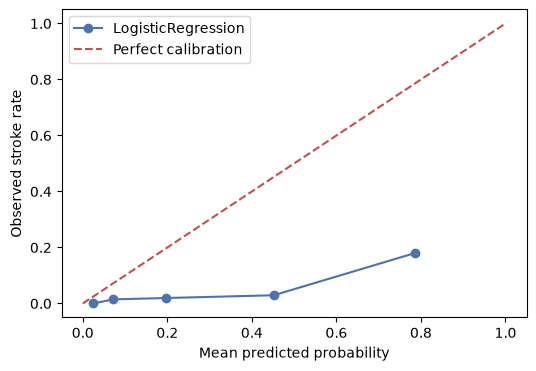

,mean_predicted,observed_rate
0,0.02,0.00
1,0.07,0.01
2,0.20,0.02
3,0.45,0.03
4,0.79,0.18


In [91]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss
import matplotlib.pyplot as plt

test_proba = lr_pipeline.predict_proba(X_test)[:, 1]
prob_true, prob_pred = calibration_curve(
    y_test, test_proba, n_bins=5, strategy='quantile'
)

calib_df = pd.DataFrame({
    'mean_predicted': prob_pred,
    'observed_rate': prob_true
}).round(2)

brier = brier_score_loss(y_test, test_proba)
brier_base = brier_score_loss(y_test, [y_train.mean()] * len(y_test))
print(f"Brier score: {brier:.3f} (constant prevalence baseline: {brier_base:.3f})")

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(prob_pred, prob_true, marker='o', color='#4C72B0', label='LogisticRegression')
ax.plot([0, 1], [0, 1], linestyle='--', color='#C44E52', label='Perfect calibration')
ax.set_xlabel('Mean predicted probability')
ax.set_ylabel('Observed stroke rate')
ax.legend()
plt.show()

calib_df

The calibration of `LogisticRegression` with `class_weight='balanced'` was checked on the test set. Patients were split into five equal-sized groups by predicted probability, and the mean predicted probability in each group was compared with the observed stroke rate.

The curve lies below the diagonal in every group: the mean predicted probabilities of 0.02, 0.07, 0.20, 0.45 and 0.79 correspond to observed stroke rates of 0.00, 0.01, 0.02, 0.03 and 0.18. The difference is largest in the upper groups. The Brier score was 0.160, compared with 0.047 for a constant prediction equal to the stroke rate in the training set. The predicted probabilities of this model are therefore not estimates of the chance of a stroke and should not be read as such. The ranking of patients is not affected by calibration, so ROC-AUC does not change with it.

In [92]:
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import roc_auc_score

models = {
    'LR balanced': clone(lr_pipeline),
    'LR no class_weight': clone(lr_pipeline).set_params(lr__class_weight=None),
    'LR balanced + sigmoid': CalibratedClassifierCV(clone(lr_pipeline), method='sigmoid', cv=5),
    'LR balanced + isotonic': CalibratedClassifierCV(clone(lr_pipeline), method='isotonic', cv=5),
}

rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    proba = model.predict_proba(X_test)[:, 1]
    rows.append({
        'model': name,
        'brier': brier_score_loss(y_test, proba),
        'roc_auc': roc_auc_score(y_test, proba),
        'mean_proba': proba.mean()
    })

pd.DataFrame(rows).round(3)

,model,brier,roc_auc,mean_proba
0,LR balanced,0.160,0.843,0.307
1,LR no class_weight,0.041,0.843,0.047
2,LR balanced + sigmoid,0.041,0.843,0.047
3,LR balanced + isotonic,0.041,0.843,0.047


To examine the source of the overestimation, `LogisticRegression` was refit without `class_weight`, and the model with `class_weight='balanced'` was recalibrated with sigmoid and isotonic methods (`CalibratedClassifierCV`, 5 folds on the training set, so the test set was not used for calibration).

ROC-AUC was 0.843 in all four variants, as expected, because the calibration is a monotonic transformation of the predicted probabilities. The Brier score fell from 0.160 for the original model to 0.041 for each of the other three variants, which is below the 0.047 of the constant prediction. The mean predicted probability fell from 0.307 to 0.047, close to the stroke rate in the test set (50 of 1,022 patients, 0.049). The overestimation therefore comes from `class_weight='balanced'`, which shifts the probabilities upward without changing their order.

The sigmoid and isotonic variants gave identical values to three decimals, so the table does not distinguish between them. The sigmoid method has fewer parameters and is less likely to overfit with 199 stroke cases in the training set. The threshold of 0.5 applies to the scale of the original model and does not carry over to the calibrated variants, so the working threshold needs to be revisited on the calibrated scale.

In [93]:
sig_model = CalibratedClassifierCV(clone(lr_pipeline), method='sigmoid', cv=5)

oof_sig = cross_val_predict(
    sig_model, X_train, y_train, cv=cv, method='predict_proba'
)[:, 1]

rows = []
for t in [0.03, 0.04, 0.05, 0.06, 0.08, 0.10]:
    pred = (oof_sig >= t).astype(int)
    rows.append({
        'threshold': t,
        'recall': recall_score(y_train, pred),
        'precision': precision_score(y_train, pred),
        'flagged': pred.mean()
    })

pd.DataFrame(rows).round(2)

,threshold,recall,precision,flagged
0,0.03,0.93,0.11,0.43
1,0.04,0.87,0.12,0.35
2,0.05,0.83,0.14,0.30
3,0.06,0.77,0.15,0.26
4,0.08,0.67,0.16,0.20
5,0.10,0.62,0.19,0.16


The threshold was varied on out-of-fold probabilities of LogisticRegression with class_weight='balanced' and sigmoid calibration, using the same StratifiedKFold splits as before, so the test set was not used for selection. On this scale the useful thresholds lie around 0.05, because the mean predicted probability is close to the stroke rate.

A threshold of 0.06 gave a recall of 0.77, a precision of 0.15 and 26% of patients flagged. These values are close to those of the uncalibrated model at a threshold of 0.5 (recall 0.79, precision 0.14, 27% flagged), as expected, because calibration does not change the ranking of patients. Lowering the threshold to 0.03 raised recall to 0.93, but 43% of patients were flagged and precision fell to 0.11. Raising it to 0.10 lowered recall to 0.62, and precision rose only to 0.19. No threshold in the range tested gave a high precision without a large loss of recall.

The threshold of 0.06 was selected as the operating point because it matches the previous working point of the uncalibrated model, which keeps the comparison with the other models consistent.

In [94]:
sig_model.fit(X_train, y_train)
sig_proba = sig_model.predict_proba(X_test)[:, 1]
sig_pred = (sig_proba >= 0.06).astype(int)

cm_sig_df = pd.DataFrame(
    confusion_matrix(y_test, sig_pred),
    index=['Actual: no stroke', 'Actual: stroke'],
    columns=['Predicted: no stroke', 'Predicted: stroke']
)
print(f"recall = {recall_score(y_test, sig_pred):.2f}, "
      f"precision = {precision_score(y_test, sig_pred):.2f}")
cm_sig_df

recall = 0.80, precision = 0.16


,Predicted: no stroke,Predicted: stroke
Actual: no stroke,754,218
Actual: stroke,10,40


The threshold of 0.06 was checked once on the test set: 40 true positives, 10 false negatives, 218 false positives and 754 true negatives (recall 0.80, precision 0.16). About 5.5 patients were flagged incorrectly for each stroke found. Compared with the uncalibrated model at a threshold of 0.5, the same 40 strokes were found with 17 fewer false alarms. With 50 stroke cases in the test set, one case changes recall by 0.02, so this difference is small relative to the sampling variation. The calibrated model is therefore equivalent to the original one for classification and differs from it in the scale of its probabilities.

In [95]:
svc_sig = CalibratedClassifierCV(clone(svc_pipeline), method='sigmoid', cv=5)
svc_sig.fit(X_train, y_train)
svc_proba = svc_sig.predict_proba(X_test)[:, 1]

compare_df = pd.DataFrame([
    {
        'model': 'LR balanced + sigmoid',
        'brier': brier_score_loss(y_test, sig_proba),
        'roc_auc': roc_auc_score(y_test, sig_proba),
        'mean_proba': sig_proba.mean()
    },
    {
        'model': 'SVC linear balanced + sigmoid',
        'brier': brier_score_loss(y_test, svc_proba),
        'roc_auc': roc_auc_score(y_test, svc_proba),
        'mean_proba': svc_proba.mean()
    }
]).round(3)
compare_df

,model,brier,roc_auc,mean_proba
0,LR balanced + sigmoid,0.041,0.843,0.047
1,SVC linear balanced + sigmoid,0.041,0.844,0.048


`SVC` with a linear kernel does not return probabilities by default, so it was calibrated with the same sigmoid method and the same number of folds as `LogisticRegression`. On the test set, the two calibrated models were indistinguishable: Brier score 0.041 for both, ROC-AUC 0.843 and 0.844, and a mean predicted probability of 0.047 and 0.048, close to the stroke rate in the test set (0.049). The difference of 0.001 in ROC-AUC is far smaller than the bootstrap interval reported above for the difference between `LogisticRegression` and `age` alone. A threshold was not tuned for `SVC`, so the two models were not compared at matched operating points.

## Final model choice

`LogisticRegression` with `class_weight='balanced'` and sigmoid calibration is kept as the working model, with a threshold of 0.06 on the calibrated scale. On recall it is comparable to `SVC` with a linear kernel: the cross-validated means are 0.794 (± 0.039) and 0.814 (± 0.029), and the difference is smaller than the fold-to-fold variation. After calibration, ROC-AUC (0.843 and 0.844) and Brier score (0.041 for both) on the test set are also the same. Neither model shows strong overfitting (train/test recall 0.82/0.80 for `LogisticRegression` and 0.83/0.78 for `SVC` with a linear kernel). `RandomForestClassifier` reached a train recall of 1.0 with a test recall of 0.00-0.16, and `SVC` with an RBF kernel 0.94/0.72.

Because the two linear models are equivalent on these metrics, `LogisticRegression` was preferred for practical reasons: it returns probabilities without an extra step and its coefficients can be read directly (see Feature importance). Without calibration, the probabilities of `LogisticRegression` with `class_weight='balanced'` were overestimated (Brier score 0.160, mean predicted probability 0.307 against a stroke rate of 0.049), and the calibrated version is the one recommended for use. At the threshold of 0.06 it reached a recall of 0.80 and a precision of 0.16 on the test set (40 true positives, 10 false negatives, 218 false positives).

The model adds little to `age` alone. ROC-AUC on the test set is 0.843 for `LogisticRegression` and 0.834 for `age` only, and the bootstrap difference of 0.009 has an interval of [-0.010, 0.028] that includes zero. A rule that flags patients at or above the 20th percentile of age among stroke cases in the training set (about 57 years) gives a recall of 0.84 and a precision of 0.13 on the test set, compared with 0.80 and 0.16 for the calibrated `LogisticRegression` at a threshold of 0.06. The predictive signal in this dataset therefore comes almost entirely from `age`, and the choice of model does not change that.

## Limitations

* **Sample size.** The test set contains 50 stroke cases, so one case changes recall by 0.02. Differences of this size between models or thresholds are within the sampling variation. Only one train/test split was used for the final evaluation.
* **Age dominates the signal.** Only 3 of 199 stroke cases in the training set occurred in patients aged 40 or younger, so the model reflects an average pattern driven by `age` and says little about younger patients. ROC-AUC of `age` alone (0.834) is close to that of the model (0.843).
* **Low precision.** At the threshold of 0.06, about 5.5 patients were flagged incorrectly for each stroke found (recall 0.80, precision 0.16). No threshold in the range tested gave a high precision without a large loss of recall.
* **Calibration and threshold.** The sigmoid calibration and the threshold were fitted on the training set (cross-validation), and the threshold was checked once on the test set. The calibration curve was drawn for the uncalibrated model only; the calibrated model was evaluated by Brier score and mean predicted probability.
* **Missing information.** Blood pressure values, lipid levels, atrial fibrillation, medication use, family history, the type of stroke (ischemic or hemorrhagic) and the date of each diagnosis are not in the dataset. Hypertension or heart disease may have been recorded after the stroke rather than before it, which this dataset cannot rule out.
* **Smoking category.** The reference category `Unknown` of `smoking_status` differs from the other categories in age (mean age 30.8 years in the training set), so the smoking coefficients are not a comparison with non-smokers.
* **Intended use.** The model was built for a classification exercise and is not a medical tool. It was not validated on external data.

## Saving the model for the app

The calibrated model and the settings needed to reproduce the preprocessing are saved to the `models` folder for the Streamlit app (`app/app.py`): the file `lr_calibrated.joblib` contains `LogisticRegression` with sigmoid calibration, and `config.json` contains the threshold of 0.06, the column order, the age-group boundaries and the median `bmi` of each age group. The medians were computed on the whole dataset before the train/test split, as in the preprocessing above.

In [96]:
import json
import os
import joblib

os.makedirs('../models', exist_ok=True)
joblib.dump(sig_model, '../models/lr_calibrated.joblib')

config = {
    'threshold': 0.06,
    'columns': list(X_train.columns),
    'age_bins': [0, 18, 40, 60, 80, 100],
    'age_labels': ['0-18', '19-40', '41-60', '61-80', '81+'],
    'bmi_median_by_age_group': {
        k: float(v)
        for k, v in df.groupby('age_group', observed=True)['bmi'].median().items()
    },
}

with open('../models/config.json', 'w') as f:
    json.dump(config, f, indent=2)

print(sorted(os.listdir('../models')))

['config.json', 'lr_calibrated.joblib']


### References

Numbers in square brackets refer to this list.

1. Bushnell C, et al. 2024 Guideline for the Primary Prevention of Stroke: A Guideline From the American Heart Association/American Stroke Association. Stroke. 2024;55(12):e344-e424. doi:10.1161/STR.0000000000000475
2. O'Donnell MJ, et al. Global and regional effects of potentially modifiable risk factors associated with acute stroke in 32 countries (INTERSTROKE): a case-control study. Lancet. 2016;388(10046). doi:10.1016/S0140-6736(16)30506-2